# 2026F - San Jose State University - CMPE-257 - project - Chris Carl

## Metadata
<div style="display: inline-block">
<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->

| Key | Value |
| :--- | :--- |
| author | Chris Carl(mailto:chris.carl@sjsu.edu) |
| date | 2026-11-13 |
| dataset | [AmesHousing.txt, save as CSV](https://jse.amstat.org/v19n3/decock/AmesHousing.txt) © 2015 American Statistical Association |

<!-- get the table rendered to the left rather than default center, the spaces after the raw html are important for markdown https://stackoverflow.com/a/78525025 -->
</div>

<!--
commands:
    ipynb CMPE-257/assignments/project/project.ipynb  # chriscarl.tools.documents
-->


# Abstract

This is my submission of project of CMPE-257 at SJSU instructed by Dr. Zara Hajihashemi in Fall 2026.

Explain the executive summary and findings. You HAVE TO. this is the first thing they see.


# TOC


<!-- # SUGGESTED TOC ORGANIZATION

# Project
# Abstract
# Table of Contents
# Question
# Answer
# Solution
## Background
## The Plan
## Code - Environment
## Code - Setup
## Code - Functions
## Code - Main
# Post Mortem
## Caveats
## Improvements
## Replication
# Appendix
## Criterion
## Changelog
-->

# Solution


## Code - Setup

The following is boilerplate I've accumulated over the years and can be safely disregarded by the reader until it becomes relevant as part of deeper inquiry.


In [11]:
# stdlib imports
import __main__
import os
import sys
import pprint
import importlib
import subprocess
# hyper-critical imports
try:
    from IPython import get_ipython
    IPYTHON_SHELL = get_ipython()  # None if running in vanilla python
except ImportError:
    IPYTHON_SHELL = None

SCRIPT_FILEPATH = ''
SCRIPT_FILENAME = ''
if IPYTHON_SHELL:
    SCRIPT_DIRPATH = str(IPYTHON_SHELL.run_line_magic('pwd', ' # %pwd is a "magic" command  https://ipython.readthedocs.io/en/stable/interactive/magics.html'))
    if hasattr(__main__, '__vsc_ipynb_file__'):  # vscode
        SCRIPT_FILEPATH = __main__.__vsc_ipynb_file__
    elif hasattr(__main__, '__session__'):  # localhost:8888/notebooks
        SCRIPT_FILEPATH = __main__.__session__
else:
    SCRIPT_FILEPATH = __file__
    SCRIPT_DIRPATH = os.path.dirname(SCRIPT_FILEPATH)

SCRIPT_FILENAME = os.path.splitext(os.path.basename(SCRIPT_FILEPATH))[0]

pprint.pprint(dict(dir=SCRIPT_DIRPATH, fp=SCRIPT_FILEPATH, fn=SCRIPT_FILENAME), indent=2)

AUTO_INSTALL = False
packages = {'imbalanced-learn': 'imblearn'}  # {'Werkzeug': 'werkzeug'}  # package name: module name
modules = ['matplotlib', 'pandas', 'ipykernel', 'ipympl', 'ipywidgets']
packages.update({m: m for m in modules})
package, module = '', ''
install_string = ' '.join(packages)
try:
    for package, module in packages.items():
        importlib.import_module(module)
except ImportError:
    print(f'"pip install {package}"', file=sys.stderr)
    if AUTO_INSTALL:
        %pip install {install_string}
    else:
        raise

# third party imports
import matplotlib.pyplot as plt

EXES = {
    'pandoc': {'exists': False},
    'latex': {'exists': False, 'win32': 'miktex', 'linux': 'texlive'},
}

for exe, data in EXES.items():
    if IPYTHON_SHELL:
        if sys.platform == 'win32':
            _res = !where.exe {exe}
            _exists = not _res[0].startswith('INFO')
        else:
            _res = !which {exe}
            _exists = bool(_res)
    else:
        if sys.platform == 'win32':
            _res = subprocess.check_output(f'where.exe {exe}', universal_newlines=True)
            _exists = not _res.startswith('INFO')
        else:
            _res = subprocess.check_output(f'which {exe}', universal_newlines=True)
            _exists = bool(_res)
    EXES[exe]['exists'] = _exists

print('pandoc:', EXES['pandoc']['exists'])
if not EXES['pandoc']['exists']:
    print('you must install pandoc!', file=sys.stderr)
    if sys.platform == 'win32':
        print('    choco install pandoc -y', file=sys.stderr)
    else:
        print('    sudo apt install pandoc -y', file=sys.stderr)
        print('    sudo yum install pandoc -y', file=sys.stderr)
        print('    dnf install pandoc -y', file=sys.stderr)
    raise RuntimeError()

print('latex:', EXES['latex']['exists'])
plt.rcParams.update(
    {
        'text.usetex': EXES['latex']['exists'],  # , 'font.family': 'Helvetica'  # requires latex installed
        'text.latex.preamble': r'\usepackage{amsmath}',  # https://stackoverflow.com/a/23856968  \text command
    }

)

# command to tell the notebook to plt.show() IN THE NOTEBOOK, otherwise you call plt.show()
%matplotlib inline
# command to tell the notebook to render interactable matplotlib, requires pip install ipympl
# %matplotlib widget

print('# pip install', install_string)
if not IPYTHON_SHELL:
    raise RuntimeError('Not sure how, but somehow this code is being run through a non-iPython environment!')


{ 'dir': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\dev',
  'fn': 'project',
  'fp': 'c:\\Users\\chris\\src\\sjsu.CMPE-257.ml-social-bot-detection\\dev\\project.ipynb'}
pandoc: True
latex: True
# pip install imbalanced-learn matplotlib pandas ipykernel ipympl ipywidgets


# Library

In [12]:
# utility functions, not logically relevant or just useful for displaying things, etc.

import os
import zipfile
import random
from IPython.display import display_markdown, display_html

from sklearn.tree import plot_tree

def unzip_file(zip_path, extract_to, password=None, print_progress=True):
    if not os.path.isfile(zip_path):
        raise FileNotFoundError(f"ZIP file not found: {zip_path}")
    os.makedirs(extract_to, exist_ok=True)
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            pwd = password.encode() if password else None
            for member in zip_ref.infolist():
                # Prevent Zip Slip vulnerability
                extracted_path = os.path.join(extract_to, member.filename)
                if member.filename.startswith('__MACOSX/._') or member.filename.split('/')[-1].startswith('._'):
                    continue

                if not os.path.realpath(extracted_path).startswith(os.path.realpath(extract_to)):
                    raise Exception(f"Unsafe file path detected: {member.filename}")

                if print_progress:
                    print(member)
                if not os.path.exists(extracted_path):
                    zip_ref.extract(member, path=extract_to, pwd=pwd)

                basename, ext = os.path.splitext(member.filename)

                if ext == '.zip':
                    unzip_file(
                        os.path.join(extract_to, member.filename), os.path.join(extract_to, member.filename[-len(basename)]), password=password, print_progress=print_progress
                    )
    except zipfile.BadZipFile:
        raise zipfile.BadZipFile(f"Invalid ZIP file: {zip_path}")
    except RuntimeError as e:
        if "password required" in str(e).lower():
            raise RuntimeError("This ZIP file is password-protected. Please provide a valid password.")
        else:
            raise

def dict_subset(dic, k=10):
    preview = {key: dic[key] for key in random.choices(list(dic.keys()), k=k)}
    return preview


def random_forest_plot(rfc, features, class_names, k=5, rand=False, title=''):
    # NOTE: targets are the string names of all unique possibilities of y-truth
    # https://stackoverflow.com/a/61037626
    title = title or f'Random Forest - First {k} Estimators'
    fig, axes = plt.subplots(nrows=1, ncols=k, figsize=(12, 8), dpi=900)
    if rand:
        idxes = random.choices(list(range(len(rfc.estimators_))), k=k)
    else:
        idxes = list(range(k))

    if k == 1:
        plot_tree(
            rfc.estimators_[idxes[0]],
            feature_names=features,
            class_names=class_names,
            filled=True,
            ax=axes
        )
        plt.title(title)
    else:
        for i, index in enumerate(idxes):
            print(len(axes), i, index)
            plot_tree(
                rfc.estimators_[index],
                feature_names=features,
                class_names=class_names,
                filled=True,
                ax=axes[i]
            )
            axes[i].set_title(f'Estimator: {index}', fontsize=11)
    fig.tight_layout()
    plt.show()
    # fig.savefig('rf_5trees.png')

def random_forest_plot_important_features(rfc, features, title='Random Forest - Feature Importance'):
    importances = rfc.feature_importances_
    plt.figure(figsize=(12, 8))
    plt.barh(features, importances, color='skyblue')
    plt.xlabel('Importance')
    plt.title(title)
    plt.gca().invert_yaxis() # Highest importance at the top
    plt.show()

def decision_tree_plot(dt, features, class_names, title='Decision Tree'):
    # NOTE: targets are the string names of all unique possibilities of y-truth
    plt.figure(figsize=(12, 8))
    plot_tree(
        dt,
        feature_names=features,
        class_names=class_names,
        filled=True,
        rounded=True
    )
    plt.title(title)
    plt.show()


# Setup

In [13]:
# Constants

PROJECT_DIRPATH = os.path.abspath(os.path.join(SCRIPT_DIRPATH, '..'))
DATA_DIRPATH = os.path.join(PROJECT_DIRPATH, 'data')

CRESCI_17_DIRPATH = os.path.join(DATA_DIRPATH, 'cresci-17')
CRESCI_17_ZIPPATH = os.path.join(CRESCI_17_DIRPATH, 'datasets_full.csv.zip')

TWIBOT_22_DIRPATH = os.path.join(DATA_DIRPATH, 'twibot-22')

DATASET_DIRECTORIES = [
    CRESCI_17_DIRPATH,
    TWIBOT_22_DIRPATH,
]
RANDOM_STATE = 42
ILOCS_ILIKE = [1, 13, 69, 420]

TARGET = 'bot'

DEBUG = True
HEAVY = True


In [14]:
# easy pre-processing functions (intuitive)

import re
import numpy as np

NANS = {np.nan, float('nan'), None , ''}

def str_digits_len(cell):
    if cell in NANS:
        return 0
    else:
        try:
            return len(re.findall(r'\d', str(cell)))
        except TypeError:
            print(cell, type(cell))
            raise

def str_len(cell):
    if cell in NANS:
        return 0
    else:
        try:
            return len(cell)
        except TypeError:
            print(cell, type(cell))
            raise

def to_datetime(date):
    # stolen from Jehu Zepeda-Silva, apply at cellular level
    date = str(date).strip()

    # nnix timestamp in milliseconds
    if date.endswith("L") or date.isdigit():
        return pd.to_datetime(int(date.rstrip("L")), unit="ms", utc=True)

    # automatically infer other date formats
    return pd.to_datetime(date, format="mixed", utc=True)
    # df[col] = df[col].dt.tz_localize(datetime.timezone.utc)  # if need for specific timezone ever comes up later

def null_treatment(df):
    for col in df.select_dtypes(include=['str']).columns:
        df[col] = df[col].fillna('')  # NOTE: OTHERWISE IT GETS EVALUATED AS A FLOAT, and you can't .apply(len) on it...
    for col in df.select_dtypes(include=['object'], exclude=['str']).columns:
        if set(df[col].unique()) == {np.nan, True}:
            df[col] = df[col].astype(bool)
    for col in df.select_dtypes(include=[bool]).columns:
        df[col] = df[col].fillna(False)
    for col in df.select_dtypes(include=[int, float]).columns:
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)
        df[col] = df[col].fillna(df[col].mean())

    return df

In [ ]:
# data pre-processing functions (unintuitive)

import sys
import pprint
import string
import math
import random
import pickle
from itertools import permutations

import ijson
import pandas as pd

GRAMS = string.ascii_letters + '0123456789_'  # '01234ABCDabcd'
GRAM_N = 2
LIKELIHOOD_PDF = {}
LIKELIHOOD_PDF_FILEPATH = os.path.join(DATA_DIRPATH, 'likelihood-pdf.pkl')

# use the genuine accounts to bootstrap the PDF
def create_2_gram_pdf(grams, n):
    # type: (str, int) -> None
    global LIKELIHOOD_PDF
    if os.path.isfile(LIKELIHOOD_PDF_FILEPATH):
        with open(LIKELIHOOD_PDF_FILEPATH, 'rb') as rb:
            LIKELIHOOD_PDF = pickle.load(rb)
            return

    pdf = {}
    for gram in grams:
        pdf[(gram,)*n] = 0
    for n_gram in permutations(grams, r=n):
        pdf[n_gram] = 0

    # stolen/modified from Jehu for consistency
    seen = set()
    total = 0
    with open(f'{TWIBOT_22_DIRPATH}/user.json', 'rb') as file:
        for user in ijson.items(file, 'item'):
            text = user.get('username') or ''
            if text in seen:
                continue
            seen.add(text)

            total_grams = len(text) - n
            for c in range(0, total_grams):
                n_gram = tuple(text[c:c+n])
                pdf[n_gram] += 1
            total += total_grams

    for k, v in pdf.items():
        pdf[k] = v / total
        if pdf[k] == 0:
            pdf[k] = sys.float_info.min  # smallest non-zero float possible so logarithm doesnt get domain error

    LIKELIHOOD_PDF = pdf
    with open(LIKELIHOOD_PDF_FILEPATH, 'wb') as wb:
        pickle.dump(LIKELIHOOD_PDF, wb)

def likelihood(cell, n=2, pdf=None):
    # https://arxiv.org/pdf/1812.05932
    # Beskow and Carley 2019 - Beskow, D. M., and Carley, K. M. 2019. Its all in a name: detecting and labeling bots by their name. Comp. and Math. Org. Theory 1–12.
    # likelihood of a screen name is defined by the geometric-mean likelihood of all bigrams in it.
    # We collected over 2M unique screen names and constructed the likelihood of all 3,969 possible bigrams
    # geometric mean is \prod_{n-gram in n-grams of text} p_{n-gram}
    #   taking the log is just as effective instead of multiplying small probabilities.
    global LIKELIHOOD_PDF
    pdf = pdf or LIKELIHOOD_PDF
    n_grams = [cell[c:c+n] for c in range(0, len(cell) - n)]
    if not n_grams:
        return sys.float_info.min
    total = len(n_grams)
    summand = sum(math.log(pdf[tuple(n_gram)]) for n_gram in n_grams)
    exp = math.exp(summand / total)
    return exp

create_2_gram_pdf(GRAMS, GRAM_N)


In [16]:
display_markdown('*illustrating how the likelihood PDF works*')
pprint.pprint(dict_subset(LIKELIHOOD_PDF, k=6), indent=4)
print(f"cresci_17 likelihood: {likelihood('cresci_17') * 100:0.9f}%, high likelihood")
print(f"twibot_22 likelihood: {likelihood('twibot_22') * 100:0.9f}%, high likelihood")
random_username = ''.join(random.choices(GRAMS, k=9))
print(f"{random_username} likelihood: {likelihood(random_username) * 100:0.9f}%, low likelihood")


{   ('8', '2'): 0.0002901500448110918,
    ('K', '6'): 6.115318972307543e-06,
    ('S', 'T'): 0.00019820185597746768,
    ('h', '4'): 6.093478547406444e-05,
    ('k', 'V'): 1.7690744169889676e-05,
    ('q', 'b'): 1.9874786659999514e-05}
cresci_17 likelihood: 0.159945005%, high likelihood
twibot_22 likelihood: 0.087613940%, high likelihood
Szomsqd85 likelihood: 0.012179950%, low likelihood


# Data Pre-Processing
- twibot-22
- twibot-22

|feature                        |type       |calculation|
|---                            |---        |---|
|statuses_count                 |count      ||
|followers_count                |count      ||
|friends_count                  |count      ||
|favourites_count               |count      ||
|listed_count                   |count      ||
|default_profile                |binary     ||
|profile_use_background_image   |binary     ||
|verified                       |binary     ||
|---                            |-          ||
|user_age                       |real       |hour difference between probe time and creation time|
|tweet_freq                     |real       |statuses_count / user_age|
|followers_growth_rate          |real       |followers_count / user_age|
|friends_growth_rate            |real       |friends_count / user_age|
|favourites_growth_rate         |real       |favourites_count / user_age|
|listed_growth_rate             |real       |listed_count / user_age|
|followers_friends_ratio        |real       |followers_count / friends_count|
|screen_name_length             |count      |length of screen name string|
|num_digits_in_screen_name      |count      |no. digits in screen name string|
|name_length                    |count      |length of name string|
|num_digits_in_name             |count      |no. digits in name string|
|description_length             |count      |length of description string|
|screen_name_likelihood         |real       |likelihood of the screen name|

In [ ]:
# data pre-processing cresci-17
import datetime
from collections import OrderedDict

CRESCI_17_DF_FILEPATH = os.path.join(DATA_DIRPATH, 'cresci-17.df')
CRESCI_17_DF_MODIFIED_FILEPATH = os.path.join(DATA_DIRPATH, 'cresci-17-modified.df')

FEATURES_CRESCI = [
    # native
    'statuses_count', 'followers_count', 'friends_count', 'favourites_count', 'listed_count', 'default_profile', 'profile_use_background_image', 'verified',
    # computed
    'user_age', 'tweet_freq', 'followers_growth_rate', 'friends_growth_rate', 'favourites_growth_rate', 'listed_growth_rate', 'followers_friends_ratio',
    # computed
    'screen_name_length', 'num_digits_in_screen_name', 'name_length', 'num_digits_in_name', 'description_length', 'screen_name_likelihood'
]

def preprocess_cresci(filepath):
    # type: (str) -> pd.DataFrame
    print(f'    "{filepath}"')
    mtime = datetime.datetime.fromtimestamp(os.stat(filepath).st_mtime, tz=datetime.timezone.utc)

    df = pd.read_csv(filepath, dtype=str)  # we're hard overwriting them anyway

    df['statuses_count'] = pd.to_numeric(df['statuses_count'])
    df['followers_count'] = pd.to_numeric(df['followers_count'])
    df['friends_count'] = pd.to_numeric(df['friends_count'])
    df['favourites_count'] = pd.to_numeric(df['favourites_count'])
    df['listed_count'] = pd.to_numeric(df['listed_count'])
    df['default_profile'] = df['default_profile'].apply(bool)
    df['profile_use_background_image'] = df['profile_use_background_image'].apply(bool)
    df['verified'] = df['verified'].apply(bool)
    df['created_at'] = df['created_at'].apply(to_datetime)

    if 'crawled_at' in df.columns:
        crawled = df['crawled_at'].apply(to_datetime)
    elif 'updated' in df.columns:
        crawled = df['updated'].apply(to_datetime)
    else:
        crawled = mtime
    df['user_age'] = (crawled - df['created_at']).dt.total_seconds() / 3600

    df['tweet_freq'] = df['statuses_count'] / df['user_age']
    df['followers_growth_rate'] = df['followers_count'] / df['user_age']
    df['friends_growth_rate'] = df['friends_count'] / df['user_age']
    df['favourites_growth_rate'] = df['favourites_count'] / df['user_age']
    df['listed_growth_rate'] = df['listed_count'] / df['user_age']
    df['followers_friends_ratio'] = df['followers_count'] / df['friends_count']

    df['screen_name_length'] = df['screen_name'].apply(str_len)
    df['num_digits_in_screen_name'] = df['screen_name'].apply(str_digits_len)
    df['name_length'] = df['name'].apply(str_len)
    df['num_digits_in_name'] = df['name'].apply(str_digits_len)
    df['description_length'] = df['description'].apply(str_len)
    df['screen_name_likelihood'] = df['screen_name'].apply(likelihood)

    df['bot'] = 'genuine_accounts' not in filepath
    df['dataset'] = os.path.splitext(os.path.basename(filepath))[0]

    return df  # wasteful to not do this here yet, but I do need the original unmodified for botometer

if os.path.isfile(CRESCI_17_DF_FILEPATH):
    print('loading from .df')
    cresci_17_df = pd.read_pickle(CRESCI_17_DF_FILEPATH)
else:
    print('unzipping')
    basename, _ = os.path.splitext(CRESCI_17_ZIPPATH)
    unzip_file(CRESCI_17_ZIPPATH, basename)

    print('preprocessing cresci-17')
    cresci_17_df = pd.DataFrame()
    for d, _, fs in os.walk(CRESCI_17_DIRPATH):
        for f in fs:
            ext = os.path.splitext(f)[-1].lower()
            if 'users' not in f or ext != '.csv':
                continue

            filepath = os.path.join(d, f)
            df = preprocess_cresci(filepath)
            if not cresci_17_df.empty:
                cresci_17_df = pd.concat([cresci_17_df, df])
            else:
                cresci_17_df = df

    cresci_17_df_modified = cresci_17_df.copy()
    cresci_17_df_modified.to_pickle(CRESCI_17_DF_MODIFIED_FILEPATH)
    del cresci_17_df_modified

    cresci_17_df = cresci_17_df[FEATURES_CRESCI + [TARGET] + ['dataset']]

    print('treating nulls cresci-17')
    cresci_17_df = null_treatment(cresci_17_df)

    print(f'writing to "{CRESCI_17_DF_FILEPATH}"')
    cresci_17_df.to_pickle(CRESCI_17_DF_FILEPATH)

display(cresci_17_df.iloc[ILOCS_ILIKE])
print(cresci_17_df.shape)
cresci_17_df.info(memory_usage='deep')
assert cresci_17_df.isnull().sum().sum() == 0, "cresci-17 nulls exist!?"


loading from .df


,statuses_count,followers_count,friends_count,favourites_count,listed_count,default_profile,profile_use_background_image,verified,user_age,tweet_freq,...,listed_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood,bot,dataset
1,1408,208,866,138,0,True,True,True,32082.971667,0.043886,...,0.0,0.240185,11,0,14,0,0,0.002515,True,users
13,30,91,527,0,0,True,True,True,40839.124444,0.000735,...,0.0,0.172676,7,0,7,0,0,0.000841,True,users
69,58,11,565,12,0,True,True,True,34756.115833,0.001669,...,0.0,0.019469,7,0,9,0,0,0.000058,True,users
420,28,15,591,9,0,True,True,True,22887.886389,0.001223,...,0.0,0.025381,13,0,7,0,0,0.001271,True,users


(28736, 23)
<class 'pandas.DataFrame'>
Index: 28736 entries, 0 to 1127
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   statuses_count                28736 non-null  int64  
 1   followers_count               28736 non-null  int64  
 2   friends_count                 28736 non-null  int64  
 3   favourites_count              28736 non-null  int64  
 4   listed_count                  28736 non-null  int64  
 5   default_profile               28736 non-null  bool   
 6   profile_use_background_image  28736 non-null  bool   
 7   verified                      28736 non-null  bool   
 8   user_age                      28736 non-null  float64
 9   tweet_freq                    28736 non-null  float64
 10  followers_growth_rate         28736 non-null  float64
 11  friends_growth_rate           28736 non-null  float64
 12  favourites_growth_rate        28736 non-null  float64
 13  listed

In [ ]:
# data pre-processing twibot-22
import datetime
from collections import OrderedDict

TWIBOT_22_DF_FILEPATH = os.path.join(DATA_DIRPATH, 'twibot-22.df')
TWIBOT_22_DF_MODIFIED_FILEPATH = os.path.join(DATA_DIRPATH, 'twibot-22-modified.df')

FEATURES_TWIBOT = [
    # native
    'statuses_count', 'followers_count', 'friends_count', 'listed_count', 'profile_use_background_image', 'verified',
    # computed
    'user_age', 'followers_growth_rate', 'friends_growth_rate', 'followers_friends_ratio',
    # computed
    'screen_name_length', 'num_digits_in_screen_name', 'name_length', 'num_digits_in_name', 'description_length', 'screen_name_likelihood'
]

if os.path.isfile(TWIBOT_22_DF_FILEPATH):
    print('loading from .df')
    twibot_22_df = pd.read_pickle(TWIBOT_22_DF_FILEPATH)
else:
    print('preprocessing twibot-22')
    twibot_user_filepath = os.path.join(TWIBOT_22_DIRPATH, 'user.json')
    twibot_label_filepath = os.path.join(TWIBOT_22_DIRPATH, 'label.csv')
    user_df = pd.read_json(twibot_user_filepath, orient='records')
    public_metrics_df = pd.json_normalize(user_df['public_metrics'])  # explode the nested dict as cols
    user_df = pd.concat([user_df, public_metrics_df], axis=1)  # glue side-by-side
    label_df = pd.read_csv(twibot_label_filepath)
    twibot_22_df = user_df.merge(label_df, how='outer', left_on='id', right_on='id', suffixes=('', '_label'))  # NOTE: suffixes when clashes happen, doesnt happen in this case, but good to know
    del user_df, label_df

    mtime = max([datetime.datetime.fromtimestamp(os.stat(filepath).st_mtime, tz=datetime.timezone.utc) for filepath in [twibot_user_filepath, twibot_label_filepath]])

    twibot_22_df['statuses_count'] = pd.to_numeric(twibot_22_df['tweet_count'])
    twibot_22_df['follower_count'] = pd.to_numeric(twibot_22_df['following_count'])
    twibot_22_df['friends_count'] = pd.to_numeric(twibot_22_df['followers_count'])
    twibot_22_df['listed_count'] = pd.to_numeric(twibot_22_df['listed_count'])
    twibot_22_df['profile_use_background_image'] = twibot_22_df['profile_image_url'].astype(bool)
    twibot_22_df['verified'] = twibot_22_df['verified'].astype(bool)
    twibot_22_df['created_at'] = twibot_22_df['created_at'].apply(to_datetime)

    twibot_22_df['user_age'] = (mtime - twibot_22_df['created_at']).dt.total_seconds() // 3600

    twibot_22_df['followers_growth_rate'] = twibot_22_df['followers_count'] / twibot_22_df['user_age']
    twibot_22_df['friends_growth_rate'] = twibot_22_df['friends_count'] / twibot_22_df['user_age']
    twibot_22_df['followers_friends_ratio'] = twibot_22_df['followers_count'] / twibot_22_df['friends_count']

    twibot_22_df['screen_name_length'] = twibot_22_df['username'].apply(str_len)
    twibot_22_df['num_digits_in_screen_name'] = twibot_22_df['username'].apply(str_digits_len)
    twibot_22_df['name_length'] = twibot_22_df['name'].apply(str_len)
    twibot_22_df['num_digits_in_name'] = twibot_22_df['name'].apply(str_digits_len)
    twibot_22_df['description_length'] = twibot_22_df['description'].apply(str_len)
    twibot_22_df['screen_name_likelihood'] = twibot_22_df['username'].apply(likelihood)

    twibot_22_df['bot'] = twibot_22_df['label'].replace({'human': False, 'bot': True}).astype(bool)

    twibot_22_df_modified = twibot_22_df.copy()
    twibot_22_df_modified.to_pickle(TWIBOT_22_DF_MODIFIED_FILEPATH)
    del twibot_22_df_modified

    twibot_22_df = twibot_22_df[FEATURES_TWIBOT + [TARGET]]

    print('treating nulls twibot-22')
    twibot_22_df = null_treatment(twibot_22_df)

    print(f'writing to "{TWIBOT_22_DF_FILEPATH}"')
    twibot_22_df.to_pickle(TWIBOT_22_DF_FILEPATH)

display(twibot_22_df.iloc[ILOCS_ILIKE])
print(twibot_22_df.shape)
twibot_22_df.info(memory_usage='deep')
assert twibot_22_df.isnull().sum().sum() == 0, "twibot-22 nulls exist!?"


loading from .df


,statuses_count,followers_count,friends_count,listed_count,profile_use_background_image,verified,user_age,followers_growth_rate,friends_growth_rate,followers_friends_ratio,screen_name_length,num_digits_in_screen_name,name_length,num_digits_in_name,description_length,screen_name_likelihood,bot
1,1397,7314,7314,78,True,False,74199.0,0.098573,0.098573,1.0,11,0,11,0,41,0.001462,False
13,226,418,418,2,True,False,74198.0,0.005634,0.005634,1.0,12,1,12,0,0,0.001562,True
69,328,85,85,0,True,False,74193.0,0.001146,0.001146,1.0,12,0,10,0,56,0.000809,False
420,7844,24,24,0,True,False,74145.0,0.000324,0.000324,1.0,13,0,19,0,48,0.003810,False


(1000000, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 17 columns):
 #   Column                        Non-Null Count    Dtype  
---  ------                        --------------    -----  
 0   statuses_count                1000000 non-null  int64  
 1   followers_count               1000000 non-null  int64  
 2   friends_count                 1000000 non-null  int64  
 3   listed_count                  1000000 non-null  int64  
 4   profile_use_background_image  1000000 non-null  bool   
 5   verified                      1000000 non-null  bool   
 6   user_age                      1000000 non-null  float64
 7   followers_growth_rate         1000000 non-null  float64
 8   friends_growth_rate           1000000 non-null  float64
 9   followers_friends_ratio       1000000 non-null  float64
 10  screen_name_length            1000000 non-null  int64  
 11  num_digits_in_screen_name     1000000 non-null  int64  
 12  name_length               

# Recreate
At this point we're recreating the original findings to the best of our ability.

We keep any class imbalances and fit the full forest with 100 trees.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report

def split_recreated(df, feature_list, target_name, random_state=RANDOM_STATE):
    X = df[feature_list]

    # encode
    # X = pd.get_dummies(X, columns=X.select_dtypes(include=['object', bool]).columns.tolist(), drop_first=False).astype(float)
    X = X.astype(float).to_numpy()  # luckly we dont have multiclass features, just convert all to floats.
    # X = X.fillna(0)  # final chance, some nan still sneaks through thanks to to_datetime errors='coerce'
    y = df[target_name].to_numpy()

    # split, scale
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_state)

    return X_train, X_test, y_train, y_test

def train(clfs, X_train, X_test, y_train, y_test, n_splits=5, random_state=RANDOM_STATE):
    class_names = [f'{klass}' for klass in np.unique(y_test)]
    results = []
    for clf in clfs:
        fold_reports = []
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

        for fold_i, (train_index, test_index) in enumerate(skf.split(X_train, y_train)):
            clf.fit(X_train[train_index], y_train[train_index])
            # note: we're treating X_test and y_test as sacred, we're NOT going to fold on those
            #   fold only on the training data (treating a piece of ITSELF as test)
            y_hat_prob = clf.predict_proba(X_train[test_index])  # returns P(class==1) \in [0, 1]
            auc = roc_auc_score(y_train[test_index], y_hat_prob[:, 1]) # takes in y, y_hat
            y_hat_class = clf.predict(X_train[test_index])  # returns K \in [K]
            report = classification_report(y_train[test_index], y_hat_class, target_names=class_names, output_dict=True)
            if not isinstance(report, dict): raise RuntimeError('bloody murder')
            report = report['weighted avg']
            report['auc'] = auc
            fold_reports.append(report)

        y_hat_prob = clf.predict_proba(X_test)  # the real enchillada
        auc = roc_auc_score(y_test, y_hat_prob[:, 1])
        y_hat_class = clf.predict(X_test)
        self_test_report = classification_report(y_test, y_hat_class, target_names=class_names, output_dict=True)
        if not isinstance(self_test_report, dict): raise RuntimeError('bloody murder')
        self_test_report = self_test_report['weighted avg']
        self_test_report['auc'] = auc

        results.append((clf, fold_reports, self_test_report))

    return results

def evaluate(clfs, X_test, y_test):
    class_names = [f'{klass}' for klass in np.unique(y_test)]
    evals = []
    for clf in clfs:
        y_hat_prob = clf.predict_proba(X_test)  # the real enchillada
        auc = roc_auc_score(y_test, y_hat_prob[:, 1])
        y_hat_class = clf.predict(X_test)
        other_test_report = classification_report(y_test, y_hat_class, target_names=class_names, output_dict=True)
        if not isinstance(other_test_report, dict): raise RuntimeError('bloody murder')
        other_test_report = other_test_report['weighted avg']
        other_test_report['auc'] = auc

        evals.append(other_test_report)

    return evals

def tablify_evaluation(models, evals):
    rows = []
    for dataset, results in models.items():
        for r, result in enumerate(results):
            clf, fold_reports, self_test_report = result  # RF1, k-fold for RF1, self-test for RF1
            other_test_report = evals[dataset][r]  # test on other dataset for RF1
            row = {'data': dataset, 'model': str(clf)}
            for key in self_test_report:
                row.update({f'{key}-self': self_test_report[key], f'{key}-other': other_test_report[key]})
                row[f'{key}-fold-avg-'] = sum([report[key] for report in fold_reports]) / len(fold_reports)
            rows.append(row)
    perf_df = pd.DataFrame(rows)
    return perf_df


In [20]:
FEATURES = [feature for feature in FEATURES_TWIBOT if feature in FEATURES_CRESCI]

################ encoding
print('recreate encode, train, test, split...')


RECREATED_FILEPATH = os.path.join(DATA_DIRPATH, 'recreated')
if not os.path.isfile(RECREATED_FILEPATH):
    ################ training
    print('recreate splits...')
    SPLITS_RECREATED = OrderedDict([
        ('cresci-17', split_recreated(cresci_17_df, FEATURES, TARGET)),
        ('twibot-22', split_recreated(twibot_22_df, FEATURES, TARGET)),
    ])

    ################ training
    print('recreate training...')
    MODELS_RECREATED = OrderedDict([
        (
            'cresci-17',
            train(
                [
                    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                ],
                *SPLITS_RECREATED['cresci-17']
            ),
        ),
        (
            'twibot-22',
            train(
                [
                    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                ],
                *SPLITS_RECREATED['twibot-22']
            ),
        ),
    ])

    ################ evaluating
    print('recreate evaluation...')
    cresci_clfs = [result[0] for result in MODELS_RECREATED['cresci-17']]
    twibot_clfs = [result[0] for result in MODELS_RECREATED['twibot-22']]
    EVALS_RECREATED = OrderedDict([
        # evaluate on other data!
        ('cresci-17', evaluate(cresci_clfs, SPLITS_RECREATED['twibot-22'][1], SPLITS_RECREATED['twibot-22'][3])),
        ('twibot-22', evaluate(twibot_clfs, SPLITS_RECREATED['cresci-17'][1], SPLITS_RECREATED['cresci-17'][3])),
    ])
    print('writing recreated...')
    with open(RECREATED_FILEPATH, 'wb') as wb:
        pickle.dump((SPLITS_RECREATED, MODELS_RECREATED, EVALS_RECREATED), wb)
else:
    print('loading recreated...')
    with open(RECREATED_FILEPATH, 'rb') as rb:
        SPLITS_RECREATED, MODELS_RECREATED, EVALS_RECREATED = pickle.load(rb)

display_markdown('*comment on class imbalances:*')
print(f'cresci-17:\n{pd.Series(SPLITS_RECREATED['cresci-17'][2]).value_counts(normalize=True)}')
print(f'twibot-22:\n{pd.Series(SPLITS_RECREATED['twibot-22'][2]).value_counts(normalize=True)}')

################ visualizing the evaluation
print('visualizing the evaluation...')
recreation_perf_df = tablify_evaluation(MODELS_RECREATED, EVALS_RECREATED)
display(recreation_perf_df)


recreate encode, train, test, split...
recreate splits...
recreate training...
recreate evaluation...
writing recreated...
cresci-17:
True     0.757842
False    0.242158
Name: proportion, dtype: float64
twibot-22:
False    0.859901
True     0.140099
Name: proportion, dtype: float64
visualizing the evaluation...


,data,model,precision-self,precision-other,precision-fold-avg-,recall-self,recall-other,recall-fold-avg-,f1-score-self,f1-score-other,f1-score-fold-avg-,support-self,support-other,support-fold-avg-,auc-self,auc-other,auc-fold-avg-
0,cresci-17,"RandomForestClassifier(n_jobs=-1, random_state...",0.988655,0.789414,0.988485,0.988632,0.773233,0.988417,0.988642,0.780916,0.988434,8621.0,300000.0,4023.0,0.998464,0.649325,0.998476
1,twibot-22,"RandomForestClassifier(n_jobs=-1, random_state...",0.849267,0.770197,0.849605,0.872370,0.277114,0.872324,0.849716,0.169403,0.850213,300000.0,8621.0,140000.0,0.822775,0.674506,0.822919


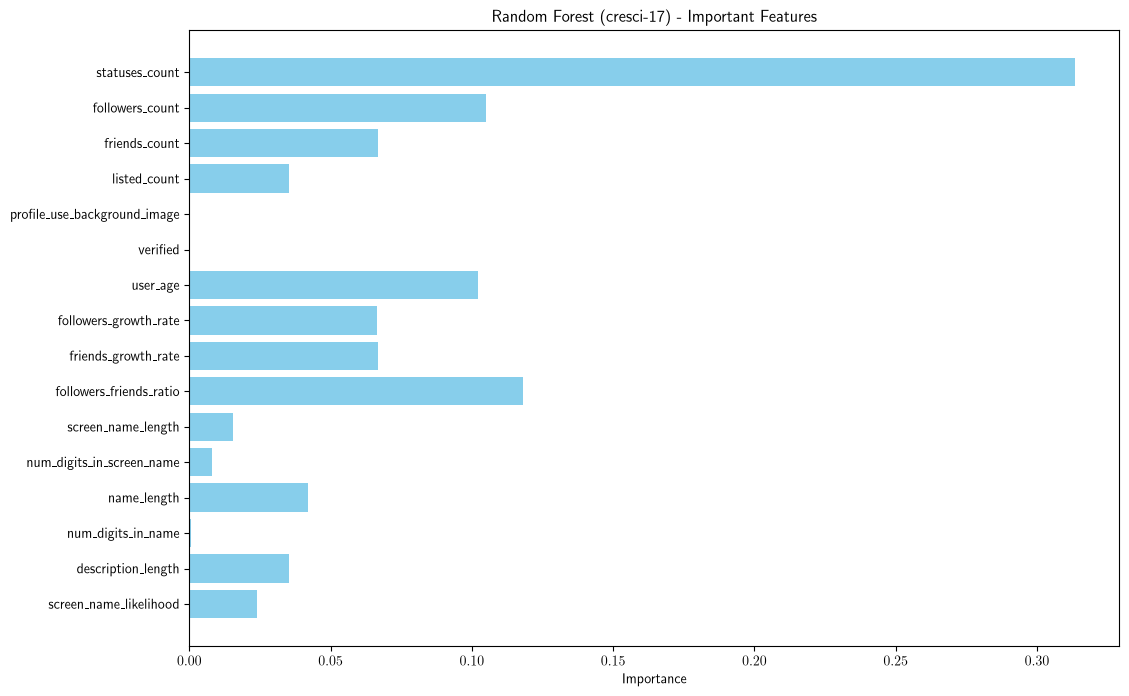

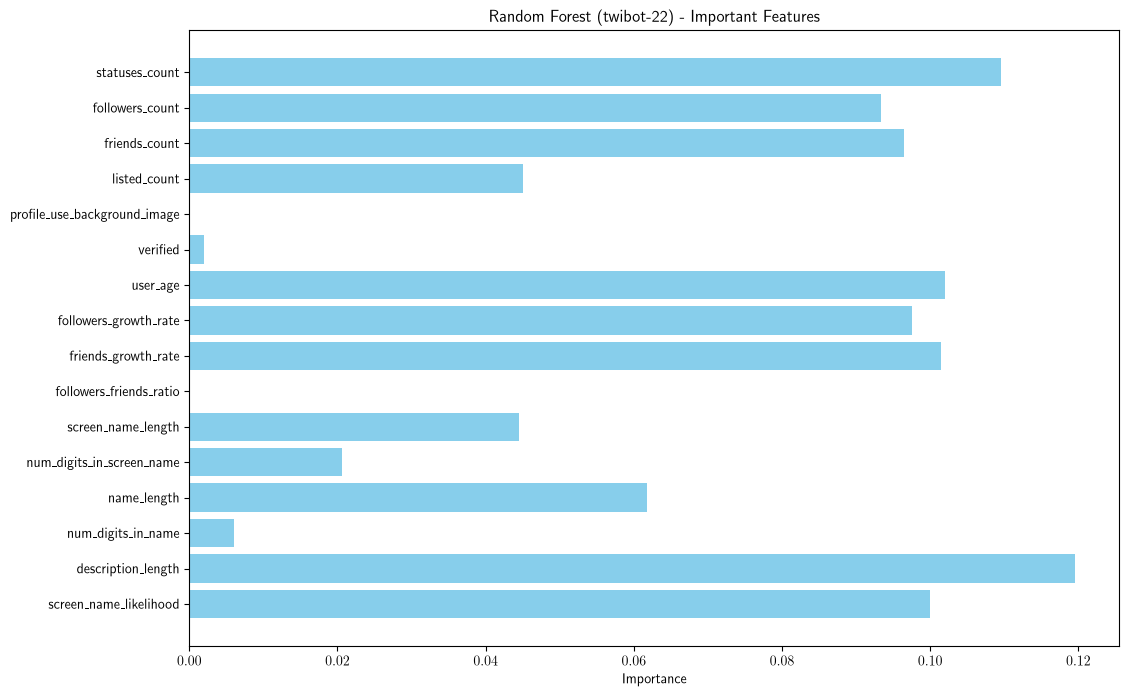

In [ ]:
ytrue = SPLITS_RECREATED['cresci-17'][-1]
TARGET_NAMES = [f'{klass}' for klass in np.unique(ytrue)]

cresci_17_rf = MODELS_RECREATED['cresci-17'][0][0]
random_forest_plot_important_features(cresci_17_rf, FEATURES, title='Random Forest (cresci-17) - Important Features')
if HEAVY:
    random_forest_plot(cresci_17_rf, FEATURES, TARGET_NAMES, k=1, rand=True, title='Random Forest (cresci-17) - 100 Trees, (One out of the 100 Estimators)')  # time consuing, may take > 5m

twibot_22_rf = MODELS_RECREATED['twibot-22'][0][0]
random_forest_plot_important_features(twibot_22_rf, FEATURES, title='Random Forest (twibot-22) - Important Features')
if HEAVY:
    random_forest_plot(twibot_22_rf, FEATURES, TARGET_NAMES, k=1, rand=True, title='Random Forest (twibot-22) - 100 Trees, (One out of the 100 Estimators)')  # time consuing, may take > 15m


# Improve
We'd like to improve the following things:
- scale, undersample
- leave one out
- recall

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler

def split_improved(df, feature_list, target_name, random_state=RANDOM_STATE, sampling_strategy=0.5):
    X = df[feature_list]

    # encode
    # X = pd.get_dummies(X, columns=X.select_dtypes(include=['object', bool]).columns.tolist(), drop_first=False).astype(float)
    X = X.astype(float).to_numpy()  # luckly we dont have multiclass features, just convert all to floats.
    # X = X.fillna(0)  # final chance, some nan still sneaks through thanks to to_datetime errors='coerce'
    y = df[target_name].to_numpy()

    # split, scale, undersample
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
    # NOTE: improvement, some need it (logistic/SVM), some dont (decision trees)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    # NOTE: improvement, get to a 50/50 class balance
    X_train, y_train = RandomUnderSampler(random_state=random_state, sampling_strategy=sampling_strategy).fit_resample(X_train, y_train)

    return X_train, X_test, y_train, y_test


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

FEATURES = [feature for feature in FEATURES_TWIBOT if feature in FEATURES_CRESCI]

IMPROVED_FILEPATH = os.path.join(DATA_DIRPATH, 'improved')
if not os.path.isfile(IMPROVED_FILEPATH):
    ################ training
    print('splitting...')
    SPLITS_IMPROVED = OrderedDict([
        ('cresci-17', split_improved(cresci_17_df, FEATURES, TARGET)),
        ('twibot-22', split_improved(twibot_22_df, FEATURES, TARGET)),
    ])

    ################ training
    print('training...')
    MODELS_IMPROVED = OrderedDict([
        (
            'cresci-17',
            train(
                [
                    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                    RandomForestClassifier(n_estimators=50, max_depth=3, random_state=RANDOM_STATE, n_jobs=-1),
                    LogisticRegression(max_iter=200, random_state=RANDOM_STATE, n_jobs=-1),
                    SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
                ],
                *SPLITS_IMPROVED['cresci-17'],
            ),
        ),
        (
            'twibot-22',
            train(
                [
                    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                    RandomForestClassifier(n_estimators=50, max_depth=3, random_state=RANDOM_STATE, n_jobs=-1),
                    LogisticRegression(max_iter=200, random_state=RANDOM_STATE, n_jobs=-1),
                    SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
                ],
                *SPLITS_IMPROVED['twibot-22'],
            ),
        ),
    ])

    ################ evaluating
    print('recreate evaluation...')
    cresci_clfs = [result[0] for result in MODELS_IMPROVED['cresci-17']]
    twibot_clfs = [result[0] for result in MODELS_IMPROVED['cresci-17']]
    EVALS_IMPROVED = OrderedDict([
        # evaluate on other data!
        ('cresci-17', evaluate(cresci_clfs, SPLITS_IMPROVED['twibot-22'][1], SPLITS_IMPROVED['twibot-22'][3])),
        ('twibot-22', evaluate(twibot_clfs, SPLITS_IMPROVED['cresci-17'][1], SPLITS_IMPROVED['cresci-17'][3])),
    ])

    print('writing improved...')
    with open(IMPROVED_FILEPATH, 'wb') as wb:
        pickle.dump((SPLITS_IMPROVED, MODELS_IMPROVED, EVALS_IMPROVED), wb)
else:
    print('loading improved...')
    with open(IMPROVED_FILEPATH, 'rb') as rb:
        SPLITS_IMPROVED, MODELS_IMPROVED, EVALS_IMPROVED = pickle.load(rb)

print('*comment on class imbalances:*')
print(f'cresci-17:\n{pd.Series(SPLITS_IMPROVED['cresci-17'][2]).value_counts(normalize=True)}')
print(f'twibot-22:\n{pd.Series(SPLITS_IMPROVED['twibot-22'][2]).value_counts(normalize=True)}')

################ visualizing the evaluation
print('visualizing the evaluation...')
improved_perf_df = tablify_evaluation(MODELS_IMPROVED, EVALS_IMPROVED)
display(improved_perf_df)


In [ ]:
raise Exception()

In [ ]:
ytrue = SPLITS_IMPROVED['cresci-17'][-1]
TARGET_NAMES = [f'{klass}' for klass in np.unique(ytrue)]

cresci_17_rf = MODELS_IMPROVED['cresci-17'][0][2]
random_forest_plot_important_features(cresci_17_rf, FEATURES, title='Random Forest (cresci-17) - Important Features')
if HEAVY:
    random_forest_plot(cresci_17_rf, FEATURES, TARGET_NAMES, k=10, rand=True, title='Random Forest (cresci-17) - 10 out of the 50 Estimators')  # time consuing, may take > 5m

twibot_22_rf = MODELS_IMPROVED['twibot-22'][0][2]
random_forest_plot_important_features(twibot_22_rf, FEATURES, title='Random Forest (twibot-22) - Important Features')
if HEAVY:
    random_forest_plot(twibot_22_rf, FEATURES, TARGET_NAMES, k=10, rand=True, title='Random Forest (twibot-22) - 10 out of the 50 Estimators')  # time consuing, may take > 15m


In [ ]:
# WARNING: DO NOT RUN THIS TOO OFTEN, ONLY 5000 users allowed to check per month!!!
import json
import botometer

BOTOMETER_API_RESULTS = os.path.join(DATA_DIRPATH, 'botometer.json')
RAPIDAPI_KEY_FILEPATH = os.path.join(DATA_DIRPATH, 'rapid-api.key')
RAPIDAPI_KEY = ''

def get_usernames():
    print('loading cresci-17 usernames')
    cresci_17_series = pd.Series()
    for d, _, fs in os.walk(CRESCI_17_DIRPATH):
        for f in fs:
            ext = os.path.splitext(f)[-1].lower()
            if 'users' not in f or ext != '.csv':
                continue

            filepath = os.path.join(d, f)
            df = pd.read_csv(filepath, dtype=str)  # we're hard overwriting them anyway
            screen_name = df['screen_name']

            if not cresci_17_series.empty:
                cresci_17_series = pd.concat([cresci_17_series, screen_name])
            else:
                cresci_17_series = screen_name

    print('loading twibot-22 usernames')
    twibot_22_series = pd.Series()
    i = 0
    with open(f'{TWIBOT_22_DIRPATH}/user.json', 'rb') as file:
        texts = []
        seen = set()
        for user in ijson.items(file, 'item'):
            text = user.get('username') or ''
            if text in seen:
                continue
            seen.add(text)

            texts.append(text)

            if len(texts) % 100000 == 0:
                i += 1
                print(f'    loaded {i * 100000}')
                screen_name = pd.Series(texts)
                if not twibot_22_series.empty:
                    twibot_22_series = pd.concat([twibot_22_series, screen_name])
                else:
                    twibot_22_series = screen_name
                texts.clear()
        screen_name = pd.Series(texts)
        twibot_22_series = pd.concat([twibot_22_series, screen_name])

    print('loading username intersection')
    return pd.Series(list(set(cresci_17_series) & set(twibot_22_series))), cresci_17_series, twibot_22_series

if os.path.isfile(RAPIDAPI_KEY_FILEPATH):
    with open(RAPIDAPI_KEY_FILEPATH, 'r', encoding='utf-8') as r:
        RAPIDAPI_KEY = r.read().strip()
if len(RAPIDAPI_KEY) != 50:
    print('WARNING: cannot complete botometer API analysis!')
else:
    if not os.path.isfile(BOTOMETER_API_RESULTS):
        common_usernames, cresci_17_usernames, twibot_22_usernames = list(get_usernames())
        print(f'using botometer API on {len(common_usernames)} common usernames')

        bomx = botometer.BotometerX(rapidapi_key=RAPIDAPI_KEY)
        all_botscores = {
            'common': common_usernames,
            'cresci-17': cresci_17_usernames,
            'twibot-22': twibot_22_usernames,
        }
        chunk_size = 500
        for key, usernames in all_botscores.items():
            for i in range(0, len(usernames), chunk_size):
                botscores = bomx.get_botscores_in_batch(usernames=usernames[i:(i+1) * chunk_size])  # ['@OSoMe_IU', 'botometer']
                # [{'bot_score': 0.09, 'timestamp': 'Sat, 27 May 2023 23:57:16 GMT', 'user_id': '2451308594', 'username': 'Botometer'}, {'bot_score': 0.21, 'timestamp': 'Thu, 25 May 2023 22:54:53 GMT', 'user_id': '187521608', 'username': 'OSoMe_IU'}]
                all_botscores[key] = botscores
        with open(BOTOMETER_API_RESULTS, 'w', encoding='utf-8') as w:
            json.dump(all_botscores, w)
    else:
        with open(BOTOMETER_API_RESULTS, 'r', encoding='utf-8') as r:
            all_botscores = json.load(r)
        print(f'loaded botometer API data from {len(all_botscores["common"])} common usernames')

    cresci_17_df_modified = pd.read_pickle(CRESCI_17_DF_MODIFIED_FILEPATH)
    twibot_22_df_modified = pd.read_pickle(TWIBOT_22_DF_MODIFIED_FILEPATH)



# Appendix


## Changelog
- 2026-11-20 00:39 - improvements work, and they are actually way better that I could have dreamed. how nice.
- 2026-11-19 23:13 - running improvements. wayyy easier once things are better organized, oh my god.
- 2026-11-19 22:11 - finally on evaluation--currently just recreating the original. if I can do that, the rest is plug and play.
- 2026-11-19 19:41 - resuming with improvements if I can
- 2026-11-19 19:00 - slides rendered
- 2026-11-19 15:35 - meeting concluded
- 2026-11-19 14:00 - meeting
- 2026-11-19 06:05 - ready for the morning except for the final model evaluation stuff
- 2026-11-19 04:23 - all building blocks are good, gonna have to redo some stuff
- 2026-11-19 03:40 - once twibot-22 was clean, model training is very straightforward. need to create the comparison "harness" next
- 2026-11-19 02:58 - really digging into twibot-22, cleaning it up is a nightmare
- 2026-11-18 22:50 - resume
- 2026-11-17 01:52 - done for the day, the model training works, maybe generalizes better
- 2026-11-17 01:30 - got the data cleaning and data engineering pipeline finished up, sketched out the different model types, fairly straightforward.
- 2026-11-16 11:15 - resuming
- 2026-11-16 05:07 - TODO: RESUME for some reason the bool isn't being applied so there are still nulls in there...
- 2026-11-16 03:36 - got the shape of what they did, implemented likelihood and a few other things, realized my pickle optimizations were useless because I need them as numbers, not strings, re-running.
- 2026-11-16 01:33 - all pickles processed w/ 184:26, saved 28.465% from 105.646GB to 75.574GB
- 2026-11-13 16:32 - initial commit
